![banner](banner.png)
# Financial Loan Risk Analysis

## Overview

This notebook uses machine learning to support loan approval decisions at FinTech Innovations. Loan applications are currently reviewed mainly by hand, which can be slow and can treat similar applications differently.

The analysis uses 20,000 historical loan applications and two models. The main model is a classifier that predicts whether a loan application was approved. The second is a regression model that predicts the existing `RiskScore`, so the score can be produced consistently.

The two kinds of error have very different costs. Denying a creditworthy applicant costs about **$8,000**, while approving an applicant who later defaults costs about **$50,000**. Models are therefore compared on business cost, not accuracy.

### Main results

- **Best model:** HistGradientBoosting, chosen on business cost from six candidate models. Its test ROC-AUC is **0.993**.
- **Decision threshold:** **0.77** instead of the default 0.50, because a wrong approval is much more expensive than a wrong denial.
- **Cost on 4,000 test applications:** **$2,514,000**, compared with **$7,648,000** for denying everyone (a **67% reduction**) and **$75,146,000** for a simple credit-score rule (a 96.7% reduction).
- **Trade-off:** at this threshold the model approves 73% of the applicants who deserved approval, so some creditworthy applicants are denied.
- **Risk score model:** a Random Forest regressor predicts `RiskScore` with an R² of **0.881** and an average error (MAE) of about **1.7 points**.
- **Key variables:** income, debt-to-income ratio, credit score, payment history, and previous defaults and bankruptcy.

The sections below cover the data exploration, preparation, model building, evaluation and recommendations.


## 1. Business Understanding

### 1.1 Current process and its limitations

Loan applications are currently reviewed manually. Officers weigh information such as income, credit history, debts and assets before deciding. This causes several problems:

- **Inconsistency:** different officers may decide differently for similar applicants.
- **Slow processing:** manual review takes longer, especially when application volumes are high.
- **Limited transparency:** it can be hard to explain exactly why a decision was made.
- **Possible bias:** personal judgement may unintentionally affect some groups of applicants.

### 1.2 Stakeholders and their needs

| Stakeholder | Main need |
|---|---|
| Loan officers | A reliable second opinion that supports their judgement |
| Risk / credit management | Lower default losses and better risk monitoring |
| Compliance / regulators | Decisions that can be explained and checked for fairness |
| Applicants | Faster and more consistent decisions |
| Bank partners | More efficient approvals without higher default losses |

### 1.3 Effect of model errors

The model can make two kinds of mistake:

- **False negative:** a creditworthy applicant is denied. Estimated cost: **$8,000** (lost profit).
- **False positive:** an applicant who will default is approved. Estimated cost: **$50,000** (default loss).

A false positive is therefore **6.25 times more expensive** than a false negative. This matters when choosing both the model and the probability threshold: a model with good accuracy can still be a poor business choice if it makes too many costly approvals.

These costs treat the historical label as the truth, so an approved application is assumed to be creditworthy and a denied one is not. `LoanApproved` records a past decision, not a confirmed repayment outcome, which is a limitation revisited in Section 9.

### 1.4 Classification and regression

The data has two possible targets:

- `LoanApproved`: a binary variable showing whether the application was approved.
- `RiskScore`: a continuous score, roughly between 29 and 84.

I use both, for different purposes.

1. **Classification is the main model.** Predicting `LoanApproved` directly addresses the approval problem. I leave `RiskScore` out of its inputs because it is already strongly related to the historical decision (correlation about -0.77). Including it would make prediction easier but would not give an independent model built from the original application information.
2. **Regression is the secondary model.** It predicts `RiskScore` from the other application variables, which could make the existing score more consistent while leaving the final decision with a loan officer.

Together, the two approaches compare automating part of the approval decision with providing a standardised risk measure that supports human judgement.

### 1.5 Evaluation metrics

No single metric gives the full picture, so I use three kinds:

1. **ROC-AUC** shows how well the model separates the two classes without fixing a probability threshold.
2. **Precision, recall and F1-score** are reported for each class separately. This is more informative than accuracy because about 76% of the applications were denied.
3. **Business cost** is the main measure for the final decision:

   ```text
   Total Cost = (False Negatives × $8,000) + (False Positives × $50,000)
   ```

This reflects the real financial impact of the two errors.

I also compare against simple baseline policies: denying everyone, approving everyone, and a basic rule that approves applicants with a credit score above the median. The credit-score rule is only a rough stand-in for manual review, since officers consider many more factors.


## 2. Data Understanding

### 2.1 Imports and setup

The required Python libraries are imported below for data handling, visualisation, statistical analysis, preprocessing, modelling and evaluation.


In [1]:
# Core data handling
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics
from scipy import stats

# Preprocessing
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

# Models
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Metrics
from sklearn.metrics import (make_scorer, roc_auc_score, roc_curve, f1_score, precision_score, recall_score,
                              confusion_matrix, ConfusionMatrixDisplay, classification_report,
                              mean_absolute_error, mean_squared_error, r2_score)
from sklearn.inspection import permutation_importance

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment ready.")


Environment ready.


### 2.2 Loading and cleaning the data

`AnnualIncome` is stored as text with a dollar sign and thousands separators (for example `"$39,948.00"`), so Python reads it as a string and it can't be used in calculations or models. I remove the `$` and commas and convert the column to a number.


In [2]:
df = pd.read_csv("financial_loan_data.csv")

print("Raw shape:", df.shape)

# Clean AnnualIncome: strip "$" and thousands-separator commas, cast to float
df['AnnualIncome'] = df['AnnualIncome'].replace(r'[\$,]', '', regex=True).astype(float)

# Sanity checks
print("Duplicate rows:", df.duplicated().sum())
print()
df.head()


Raw shape: (20000, 35)
Duplicate rows: 0



,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,Experience,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,...,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
0,45,39948.0,617,Employed,Master,22,13152,48,Married,2,...,3329.000000,0.724972,11,126928,0.199652,0.227590,419.805992,0.181077,0,49.0
1,38,39709.0,628,Employed,Associate,15,26045,48,Single,1,...,3309.083333,0.935132,3,43609,0.207045,0.201077,794.054238,0.389852,0,52.0
2,47,40724.0,570,Employed,Bachelor,26,17627,36,NaN,2,...,3393.666667,0.872241,6,5205,0.217627,0.212548,666.406688,0.462157,0,52.0
3,58,69084.0,545,Employed,High School,34,37898,96,Single,1,...,5757.000000,0.896155,5,99452,0.300398,0.300911,1047.506980,0.313098,0,54.0
4,37,103264.0,594,Employed,Associate,17,9184,36,Married,1,...,8605.333333,0.941369,5,227019,0.197184,0.175990,330.179140,0.070210,1,36.0


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         20000 non-null  int64  
 1   AnnualIncome                20000 non-null  float64
 2   CreditScore                 20000 non-null  int64  
 3   EmploymentStatus            20000 non-null  object 
 4   EducationLevel              19099 non-null  object 
 5   Experience                  20000 non-null  int64  
 6   LoanAmount                  20000 non-null  int64  
 7   LoanDuration                20000 non-null  int64  
 8   MaritalStatus               18669 non-null  object 
 9   NumberOfDependents          20000 non-null  int64  
 10  HomeOwnershipStatus         20000 non-null  object 
 11  MonthlyDebtPayments         20000 non-null  int64  
 12  CreditCardUtilizationRate   20000 non-null  float64
 13  NumberOfOpenCreditLines     200

In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Age,20000.0,39.752600,11.622713,18.000000,32.000000,40.000000,48.000000,8.000000e+01
AnnualIncome,20000.0,59161.473550,40350.845168,15000.000000,31679.000000,48566.000000,74391.000000,4.853410e+05
CreditScore,20000.0,571.612400,50.997358,343.000000,540.000000,578.000000,609.000000,7.120000e+02
Experience,20000.0,17.522750,11.316836,0.000000,9.000000,17.000000,25.000000,6.100000e+01
LoanAmount,20000.0,24882.867800,13427.421217,3674.000000,15575.000000,21914.500000,30835.000000,1.847320e+05
LoanDuration,20000.0,54.057000,24.664857,12.000000,36.000000,48.000000,72.000000,1.200000e+02
NumberOfDependents,20000.0,1.517300,1.386325,0.000000,0.000000,1.000000,2.000000,5.000000e+00
MonthlyDebtPayments,20000.0,454.292700,240.507609,50.000000,286.000000,402.000000,564.000000,2.919000e+03
CreditCardUtilizationRate,20000.0,0.286381,0.159793,0.000974,0.160794,0.266673,0.390634,9.173801e-01
NumberOfOpenCreditLines,20000.0,3.023350,1.736161,0.000000,2.000000,3.000000,4.000000,1.300000e+01


### 2.3 Missing values and data quality

I check how many values are missing in each column and what share of the data they represent. The reason a value is missing matters as much as the count, because it decides how the gap should be handled: a blank may be a data error, or it may carry meaning of its own.


In [5]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_summary


,missing_count,missing_pct
MaritalStatus,1331,6.65
EducationLevel,901,4.50
SavingsAccountBalance,572,2.86


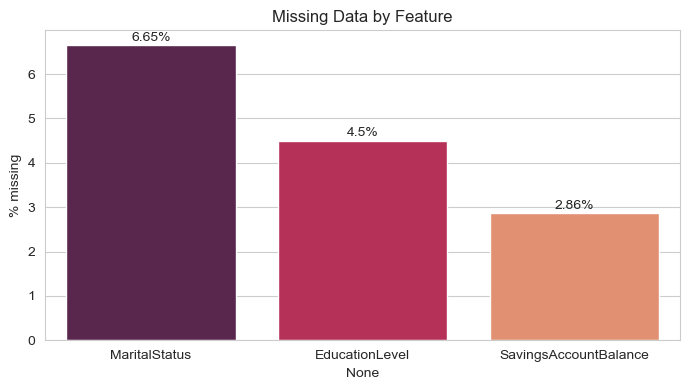

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=missing_summary.index, y=missing_summary['missing_pct'], hue=missing_summary.index,
            palette='rocket', legend=False, ax=ax)
ax.set_ylabel('% missing')
ax.set_title('Missing Data by Feature')
for i, v in enumerate(missing_summary['missing_pct']):
    ax.text(i, v + 0.1, f"{v}%", ha='center')
plt.tight_layout()
plt.show()


### Interpretation of the missing values

The three columns with missing values need different treatments, because a blank can mean different things in each.

- **`MaritalStatus` (about 6.7% missing) and `EducationLevel` (about 4.5% missing):** these are categorical, so I keep the blanks as their own **"Unknown"** category. Filling them with the most common value would assume that every missing response matches the majority group, and the data gives no evidence for that.
- **`SavingsAccountBalance` (about 2.9% missing):** a blank here may mean the applicant has no savings account, so I fill it with **0** and add a **missing-value indicator** column. This is an assumption I can't confirm from the data.

With the indicator, the model can tell a reported balance of 0 from a missing one, so that information isn't lost.

### 2.4 Target variable distributions and class imbalance

The next step is to look at the distribution of `LoanApproved` and `RiskScore`. This helps to understand the two targets before building the models.


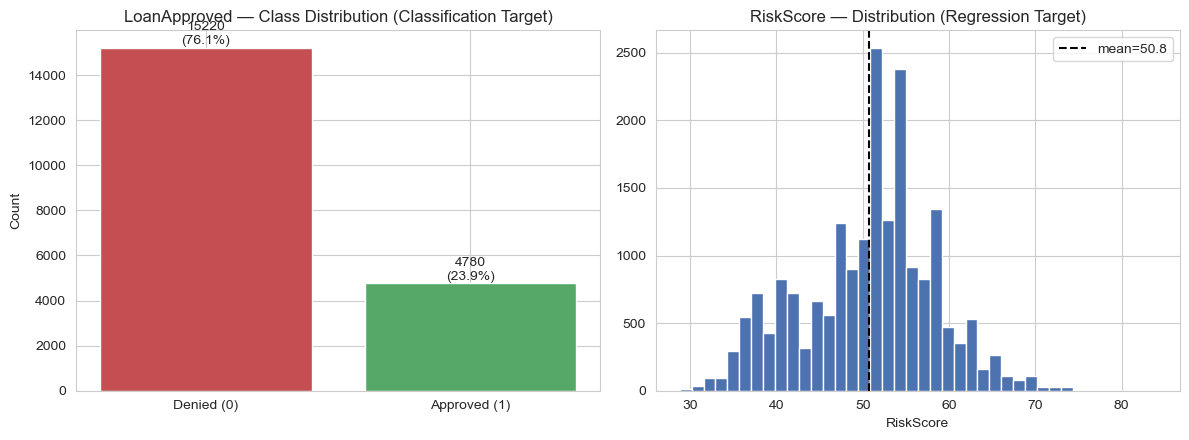

Approval rate: 23.9% approved, 76.1% denied
Imbalance ratio: 3.18 : 1 (denied:approved)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

approval_counts = df['LoanApproved'].value_counts().sort_index()
axes[0].bar(['Denied (0)', 'Approved (1)'], approval_counts.values, color=['#c44e52', '#55a868'])
for i, v in enumerate(approval_counts.values):
    axes[0].text(i, v + 150, f"{v}\n({v/len(df)*100:.1f}%)", ha='center')
axes[0].set_title('LoanApproved — Class Distribution (Classification Target)')
axes[0].set_ylabel('Count')

axes[1].hist(df['RiskScore'], bins=40, color='#4c72b0', edgecolor='white')
axes[1].axvline(df['RiskScore'].mean(), color='black', linestyle='--', label=f"mean={df['RiskScore'].mean():.1f}")
axes[1].set_title('RiskScore — Distribution (Regression Target)')
axes[1].set_xlabel('RiskScore')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Approval rate: {df['LoanApproved'].mean()*100:.1f}% approved, {(1-df['LoanApproved'].mean())*100:.1f}% denied")
print(f"Imbalance ratio: {(df['LoanApproved']==0).sum() / (df['LoanApproved']==1).sum():.2f} : 1 (denied:approved)")


### Class imbalance

About **76% of applications were denied** (15,220 of 20,000) and 24% were approved. A model that denied everyone would be about 76% accurate while approving no one, so accuracy alone is misleading here.

I therefore don't use accuracy as the main measure. I use ROC-AUC, F1 and the **business cost** defined earlier, which penalises the more expensive error more heavily. To handle the imbalance, I use stratified splits and cross-validation so both classes keep the same proportions, and class weighting in the models where it is available.


### 2.5 Relationship between the two targets

I compare `RiskScore` with the historical `LoanApproved` decision to see whether the two targets are related.


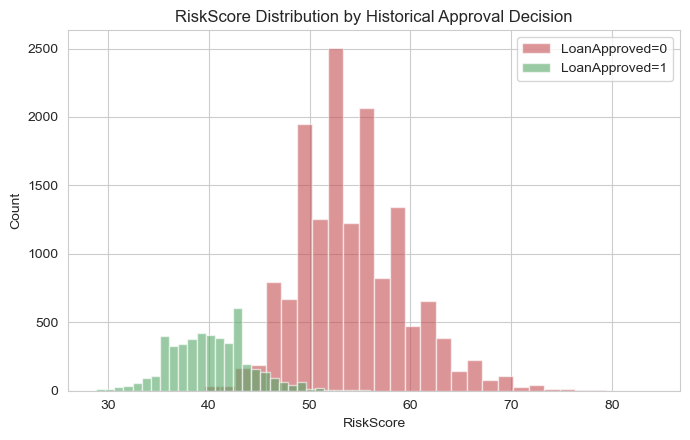

                count       mean       std   min   25%   50%   75%   max
LoanApproved                                                            
0             15220.0  54.106307  5.301985  38.0  50.0  54.0  57.0  84.0
1              4780.0  40.133389  3.879725  28.8  37.6  40.0  42.4  56.0

Correlation(RiskScore, LoanApproved) = -0.766


In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for label, color in [(0, '#c44e52'), (1, '#55a868')]:
    subset = df[df['LoanApproved'] == label]['RiskScore']
    ax.hist(subset, bins=30, alpha=0.6, label=f"LoanApproved={label}", color=color)
ax.set_xlabel('RiskScore')
ax.set_ylabel('Count')
ax.set_title('RiskScore Distribution by Historical Approval Decision')
ax.legend()
plt.tight_layout()
plt.show()

print(df.groupby('LoanApproved')['RiskScore'].describe())
print()
print(f"Correlation(RiskScore, LoanApproved) = {df['RiskScore'].corr(df['LoanApproved']):.3f}")


`RiskScore` is strongly related to the historical approval decision, with a correlation of about **-0.77**: lower risk scores are generally linked to approval.

The relationship is not perfect, though. The two groups overlap, especially for scores of roughly 40 to 55. This suggests the historical decisions were not based on the risk score alone, and that similar applicants were not always treated the same way.

Because `RiskScore` is so closely tied to the outcome, I treat it as a separate target for the regression model and leave it out of the classification features


### 2.6 Feature categorisation

I group the variables according to the type of data they contain. This is important because the different variable types need different preprocessing methods.

| Type | Features |
|---|---|
| **Numerical** | Age, AnnualIncome, CreditScore, Experience, LoanAmount, LoanDuration, MonthlyDebtPayments, CreditCardUtilizationRate, NumberOfOpenCreditLines, NumberOfCreditInquiries, DebtToIncomeRatio, PaymentHistory, LengthOfCreditHistory, SavingsAccountBalance, CheckingAccountBalance, TotalAssets, TotalLiabilities, MonthlyIncome, UtilityBillsPaymentHistory, JobTenure, NetWorth, BaseInterestRate, InterestRate, MonthlyLoanPayment, TotalDebtToIncomeRatio, NumberOfDependents |
| **Binary** | PreviousLoanDefaults, BankruptcyHistory |
| **Nominal categorical** | EmploymentStatus, MaritalStatus, HomeOwnershipStatus, LoanPurpose |
| **Ordinal categorical** | EducationLevel |
| **Targets** | LoanApproved, RiskScore |

`EducationLevel` has a natural order from High School through Doctorate, so it is treated differently from the nominal categorical variables.


In [9]:
for col in ['EmploymentStatus', 'EducationLevel', 'MaritalStatus', 'HomeOwnershipStatus', 'BankruptcyHistory', 'LoanPurpose']:
    print(f"{col}: {sorted(df[col].dropna().unique().tolist())}")


EmploymentStatus: ['Employed', 'Self-Employed', 'Unemployed']
EducationLevel: ['Associate', 'Bachelor', 'Doctorate', 'High School', 'Master']
MaritalStatus: ['Divorced', 'Married', 'Single', 'Widowed']
HomeOwnershipStatus: ['Mortgage', 'Other', 'Own', 'Rent']
BankruptcyHistory: ['No', 'Yes']
LoanPurpose: ['Auto', 'Debt Consolidation', 'Education', 'Home', 'Other']


### 2.7 Univariate distributions of key numerical variables

I examine the distributions of some important numerical variables such as income, credit score, debt-to-income ratio, net worth, loan amount and interest rate.


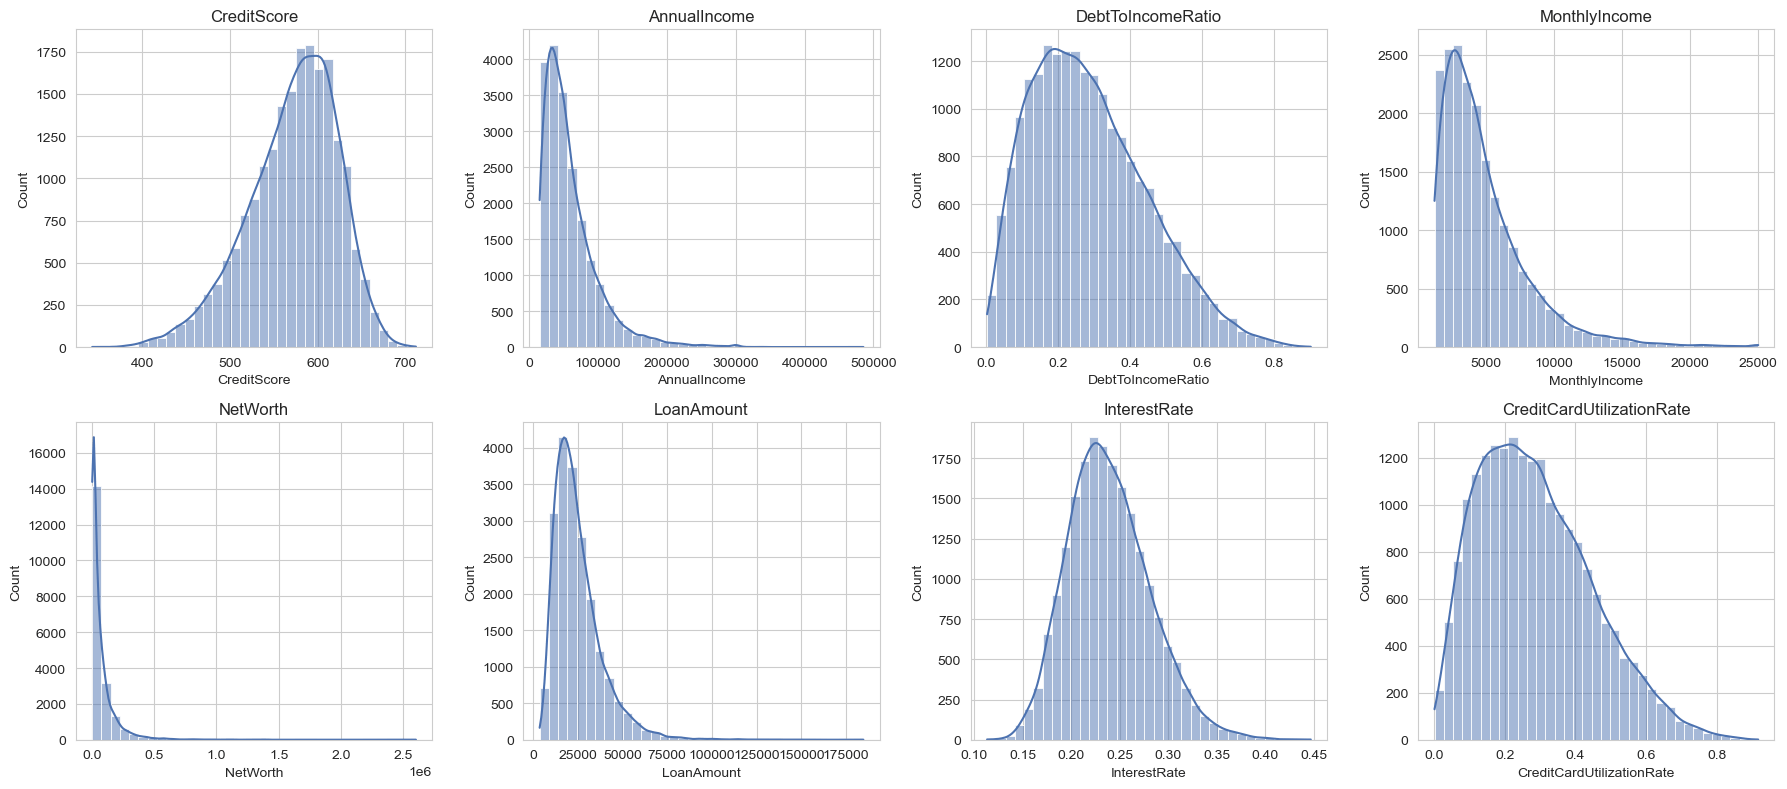

In [10]:
key_numeric = ['CreditScore', 'AnnualIncome', 'DebtToIncomeRatio', 'MonthlyIncome',
               'NetWorth', 'LoanAmount', 'InterestRate', 'CreditCardUtilizationRate']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, key_numeric):
    sns.histplot(df[col], bins=35, kde=True, ax=ax, color='#4c72b0')
    ax.set_title(col)
plt.tight_layout()
plt.show()


### Observations

`AnnualIncome`, `NetWorth` and `LoanAmount` have right-skewed distributions. This means that most observations are at the lower or middle values, with a smaller number of applicants having much higher values.

This is common in financial data. Scaling is useful for models such as Logistic Regression, while tree-based models are generally less affected by the different variable scales.


### Check for Outliers on key financial variables

I check the main financial variables for possible outliers using the IQR method.


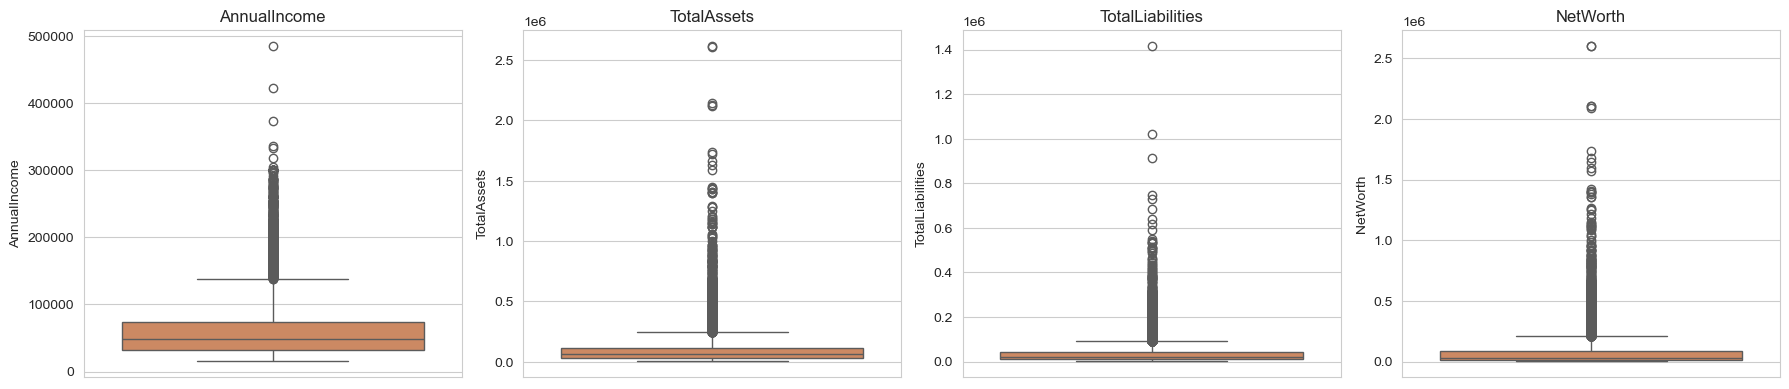

AnnualIncome: 947 IQR-outliers (4.7%), range=[15000, 485341]
TotalAssets: 1442 IQR-outliers (7.2%), range=[2098, 2619627]
TotalLiabilities: 1533 IQR-outliers (7.7%), range=[372, 1417302]
NetWorth: 1564 IQR-outliers (7.8%), range=[1000, 2603208]
LoanAmount: 746 IQR-outliers (3.7%), range=[3674, 184732]


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ['AnnualIncome', 'TotalAssets', 'TotalLiabilities', 'NetWorth']):
    sns.boxplot(y=df[col], ax=ax, color='#dd8452')
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in ['AnnualIncome', 'TotalAssets', 'TotalLiabilities', 'NetWorth', 'LoanAmount']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"{col}: {n_out} IQR-outliers ({n_out/len(df)*100:.1f}%), range=[{df[col].min():.0f}, {df[col].max():.0f}]")


### Outliers

I used boxplots and the IQR rule (values more than 1.5 × IQR beyond the quartiles) to check the main financial variables. Between 3.7% and 7.8% of values were flagged as outliers in each column, for example 947 for `AnnualIncome` (4.7%) and 1,564 for `NetWorth` (7.8%).

The variables are strongly right-skewed: most applicants have modest income and assets, and a smaller group has very large values. These values are positive and within plausible financial ranges, so they look like genuine high-income or high-wealth applicants and not data-entry errors. I therefore **keep them**, because removing them would discard real applicants.

Tree-based models are not much affected by extreme values. For Logistic Regression, scaling puts the features on a comparable scale, but it doesn't remove the skew, so the linear model may be less accurate on very large values.


### 2.9 Categorical variables and approval rate

I compare the approval rate across the main categorical variables to see whether there are noticeable differences between groups.


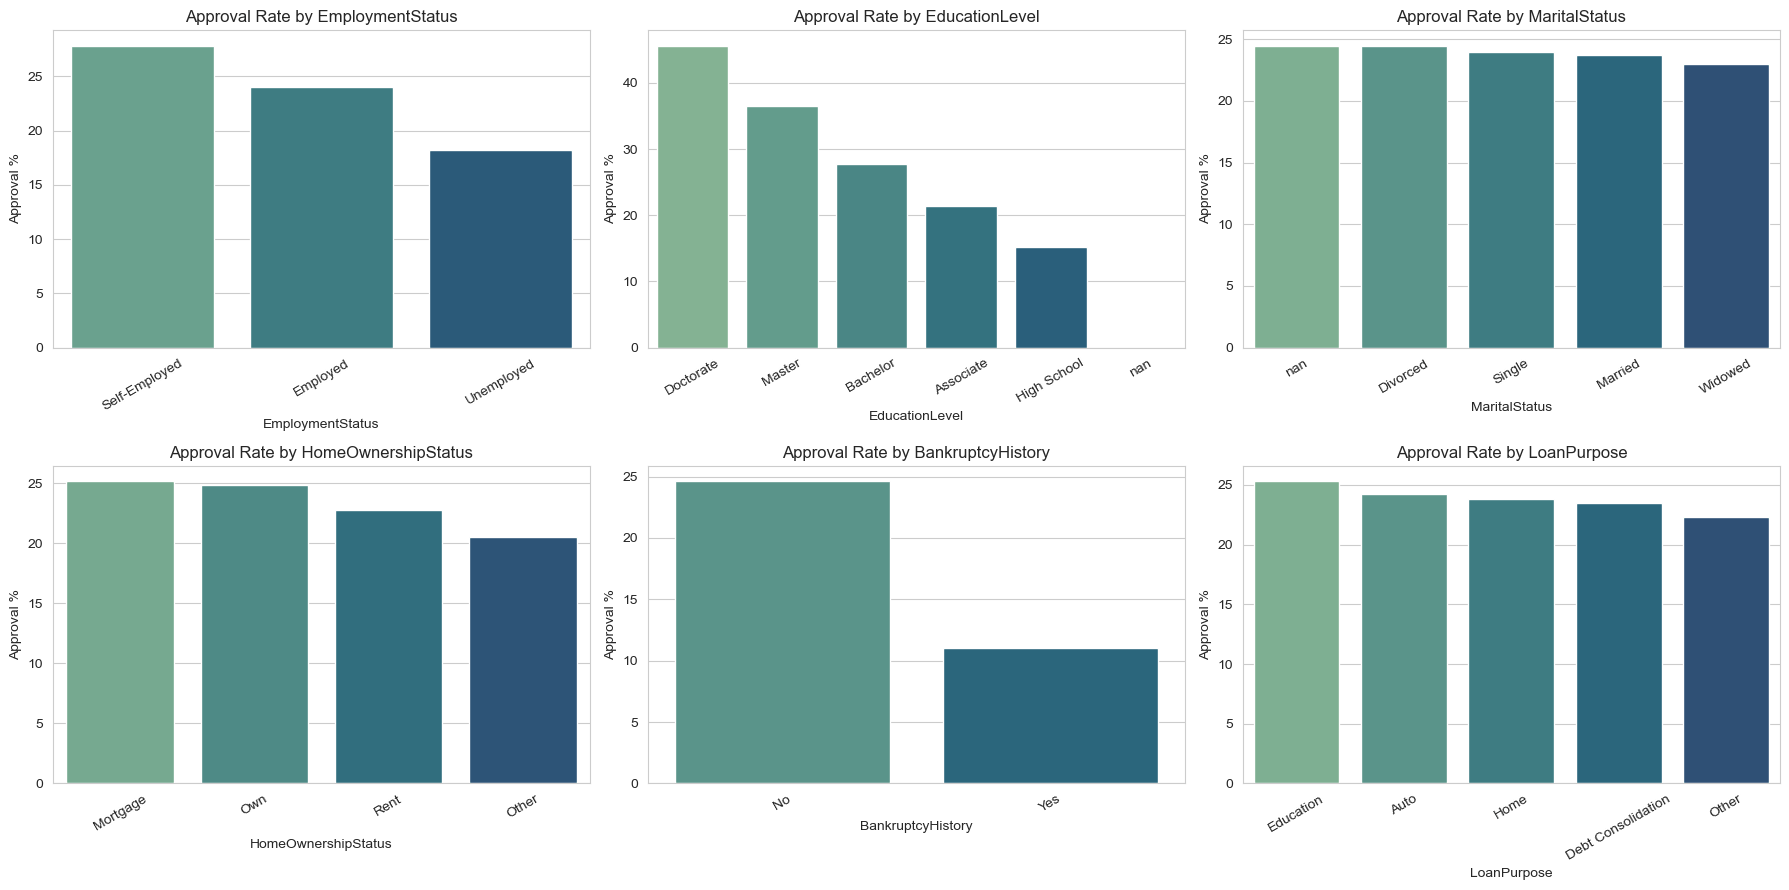

In [12]:
cat_cols = ['EmploymentStatus', 'EducationLevel', 'MaritalStatus', 'HomeOwnershipStatus', 'BankruptcyHistory', 'LoanPurpose']

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, cat_cols):
    rates = df.groupby(col, dropna=False)['LoanApproved'].mean().sort_values(ascending=False) * 100
    rates.index = rates.index.astype(str)
    sns.barplot(x=rates.index, y=rates.values, hue=rates.index, palette='crest', legend=False, ax=ax)
    ax.set_title(f'Approval Rate by {col}')
    ax.set_ylabel('Approval %')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()


### Observation

Bankruptcy history and employment status show noticeable differences in approval rates. This suggests that these variables contain useful information for predicting the historical approval decision, so they should be retained in the modelling process.


### 2.10 Correlation structure and relationships between variables

I examine the correlation matrix and selected pair relationships to identify variables that have strong relationships with the approval decision and with each other.


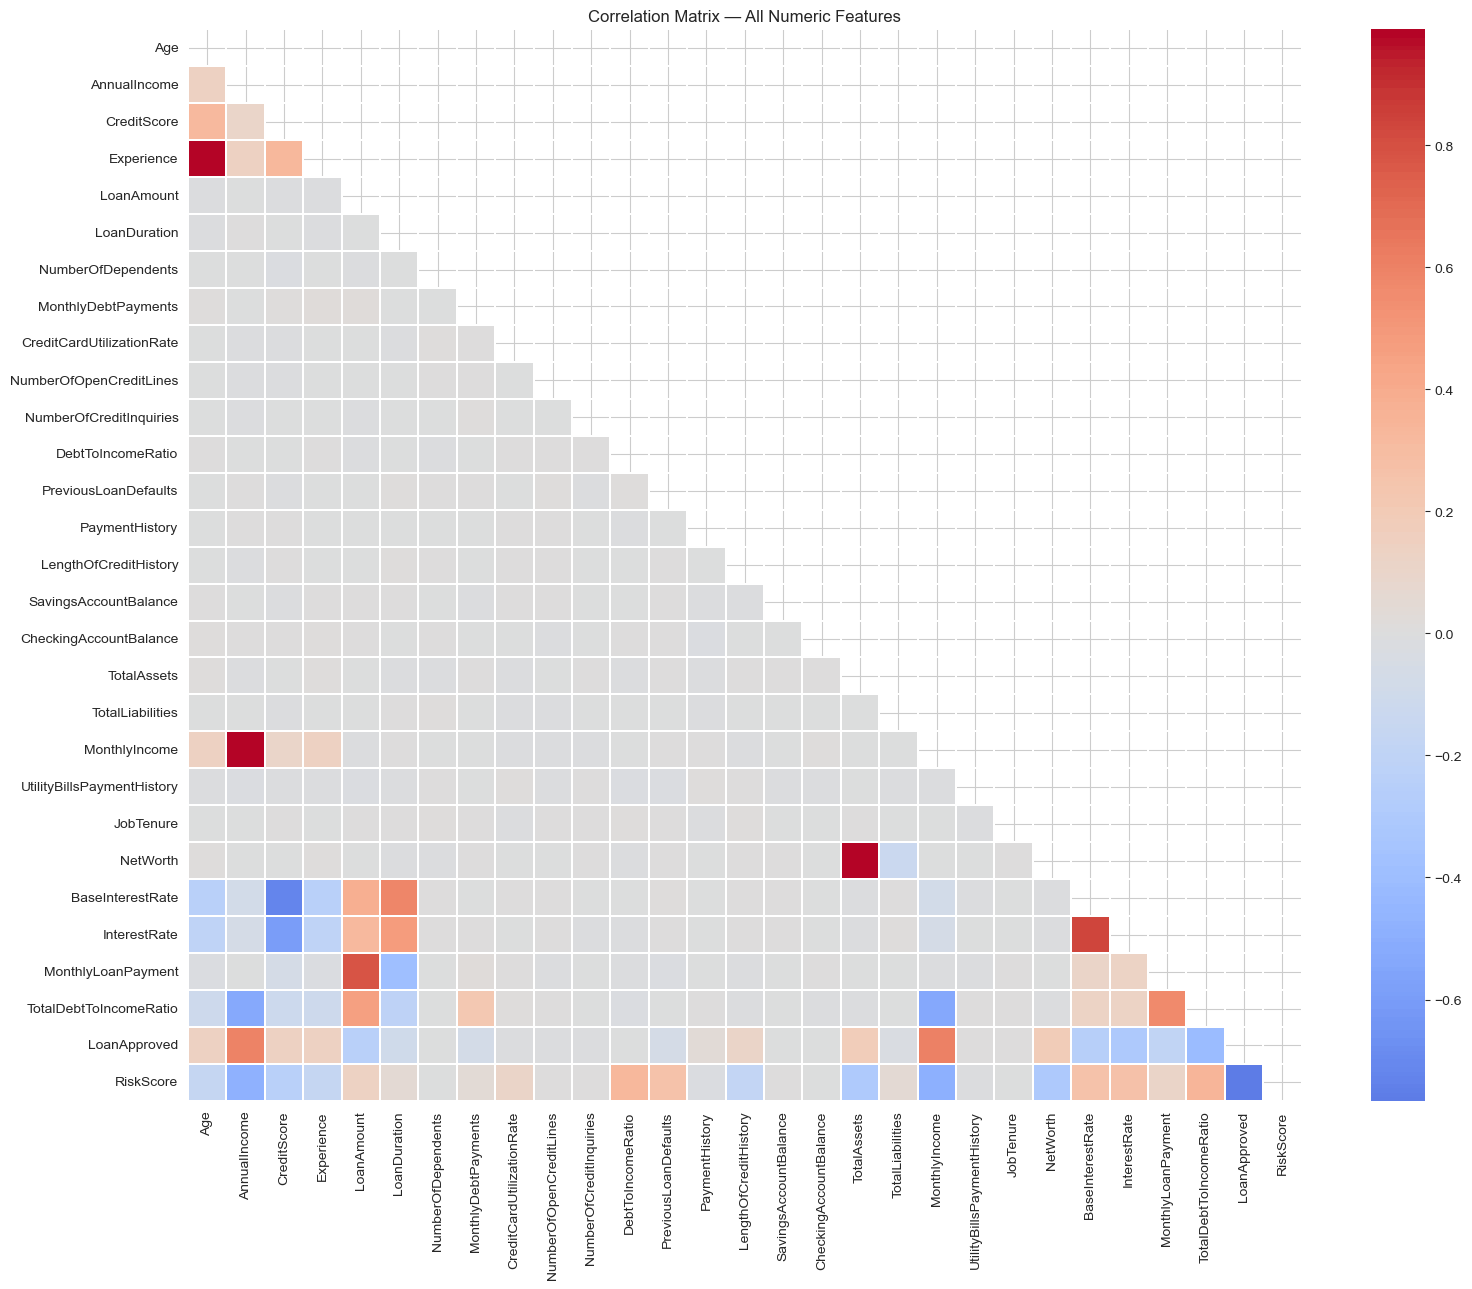

In [13]:
numeric_for_corr = df.select_dtypes(include=[np.number]).columns.tolist()
corr = df[numeric_for_corr].corr()

fig, ax = plt.subplots(figsize=(16, 13))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, annot=False, ax=ax, linewidths=0.3)
ax.set_title('Correlation Matrix — All Numeric Features')
plt.tight_layout()
plt.show()


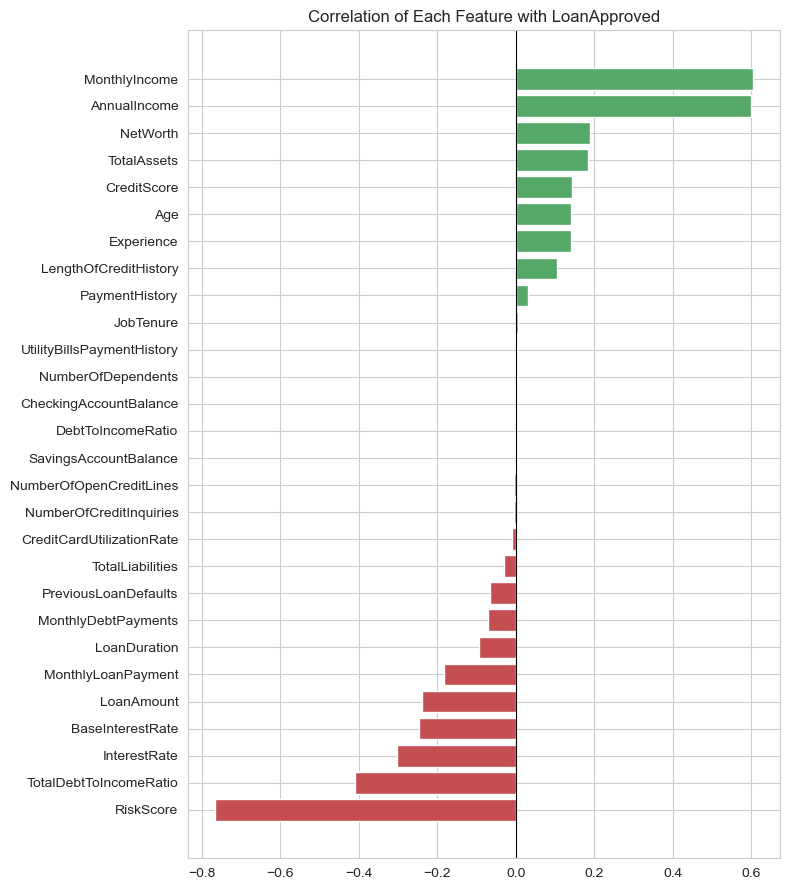

In [14]:
corr_target = corr['LoanApproved'].drop(['LoanApproved']).sort_values()
fig, ax = plt.subplots(figsize=(8, 9))
colors = ['#c44e52' if v < 0 else '#55a868' for v in corr_target.values]
ax.barh(corr_target.index, corr_target.values, color=colors)
ax.set_title('Correlation of Each Feature with LoanApproved')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()


`RiskScore` has the strongest correlation with the historical approval decision (about **-0.77**), but I do not use it as a predictor in the main classification model . Among the remaining features, the strongest relationships are `MonthlyIncome` (about **+0.60**) and `TotalDebtToIncomeRatio` (about **-0.41**): higher income goes with approval, and a higher debt burden goes with denial.

This fits a lending perspective, since income and existing debt show whether an applicant can afford a loan. These are simple linear correlations, though, so they don't show cause and effect, and they can miss non-linear or combined effects. The modelling stage tests these relationships more fully.

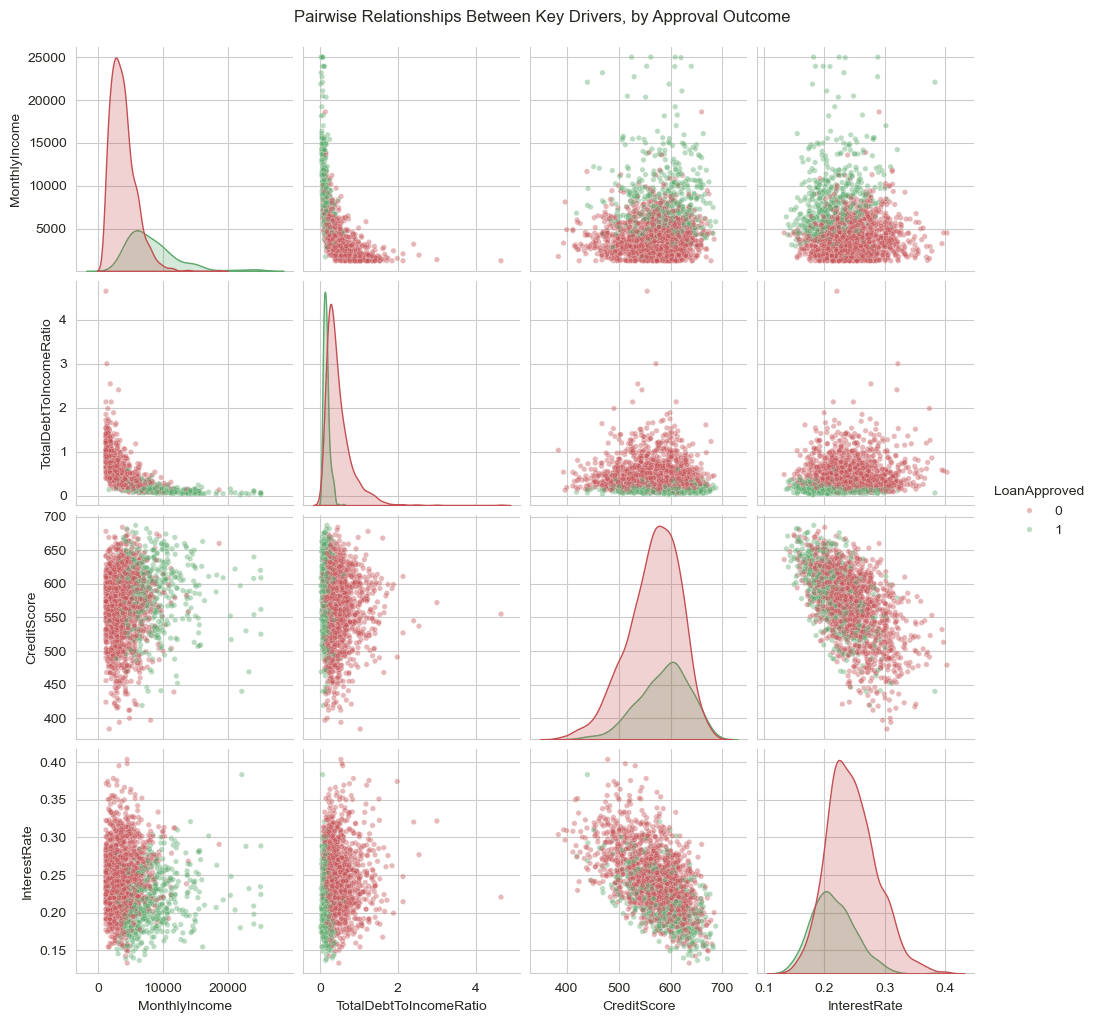

In [15]:
pairplot_cols = ['MonthlyIncome', 'TotalDebtToIncomeRatio', 'CreditScore', 'InterestRate', 'LoanApproved']
sample = df[pairplot_cols].sample(2000, random_state=RANDOM_STATE)  # sample for rendering speed
g = sns.pairplot(sample, hue='LoanApproved', palette={0: '#c44e52', 1: '#55a868'}, diag_kind='kde',
                 plot_kws={'alpha': 0.4, 's': 15})
g.fig.suptitle('Pairwise Relationships Between Key Drivers, by Approval Outcome', y=1.02)
plt.show()


### 2.11 Statistical significance checks

I use statistical tests to check whether some of the relationships observed during the exploratory analysis are statistically significant.


In [16]:
# 1) Independent t-test: is CreditScore significantly different between approved vs denied?
approved_scores = df.loc[df['LoanApproved'] == 1, 'CreditScore']
denied_scores = df.loc[df['LoanApproved'] == 0, 'CreditScore']
t_stat, p_val = stats.ttest_ind(approved_scores, denied_scores, equal_var=False)
print(f"T-test CreditScore (approved vs denied): t={t_stat:.2f}, p={p_val:.2e}")

# 2) Chi-square: is EmploymentStatus associated with LoanApproved?
contingency = pd.crosstab(df['EmploymentStatus'], df['LoanApproved'])
chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)
print(f"Chi-square EmploymentStatus x LoanApproved: chi2={chi2:.2f}, p={p_chi:.2e}")

# 3) Independent t-test: MonthlyIncome
t_stat2, p_val2 = stats.ttest_ind(df.loc[df['LoanApproved']==1, 'MonthlyIncome'],
                                   df.loc[df['LoanApproved']==0, 'MonthlyIncome'], equal_var=False)
print(f"T-test MonthlyIncome (approved vs denied): t={t_stat2:.2f}, p={p_val2:.2e}")


T-test CreditScore (approved vs denied): t=20.68, p=1.08e-92
Chi-square EmploymentStatus x LoanApproved: chi2=38.51, p=4.35e-09
T-test MonthlyIncome (approved vs denied): t=76.46, p=0.00e+00


All three tests are significant at **p < 0.001**:

- **CreditScore (t-test):** approved and denied applicants differ in average credit score (t = 20.68).
- **MonthlyIncome (t-test):** the difference in average monthly income is much larger (t = 76.46).
- **EmploymentStatus (chi-square):** employment status is associated with the approval decision (χ² = 38.51).

These results support the patterns in the earlier plots: credit score, income and employment status are all related to the historical approval decision in this dataset.

Statistical significance is not the same as predictive usefulness. With 20,000 rows, even a small difference can be significant, so these tests only show that a relationship exists, not how strong it is. I therefore judge the variables by how much they contribute in the models (Section 7).

## 3. Data Preparation

### 3.1 Preprocessing strategy

I use a `ColumnTransformer` with separate pipelines for numerical, categorical and ordinal variables. This makes the preprocessing consistent and also helps prevent data leakage because the transformations are fitted as part of the model pipeline.

| Branch | Main treatment |
|---|---|
| Numerical | Imputation and scaling where required |
| Categorical | Missing values handled and categories one-hot encoded |
| Ordinal | Missing values handled and education levels encoded in order |

The same preprocessing is then used for the different models so that the comparison is fair.


In [17]:
# --- Primary classification target: LoanApproved -----------------------------
# RiskScore is deliberately excluded as an input feature (Section 1.4)
TARGET_CLF = 'LoanApproved'
X = df.drop(columns=['LoanApproved', 'RiskScore'])
y = df[TARGET_CLF]

# --- Feature type groups -----------------------------------------------------
ordinal_col = ['EducationLevel']
edu_order = ['Unknown', 'High School', 'Associate', 'Bachelor', 'Master', 'Doctorate']

binary_col = ['BankruptcyHistory']
nominal_cols = ['EmploymentStatus', 'MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose']

all_other_cols = ordinal_col + binary_col + nominal_cols
numeric_cols = [c for c in X.columns if c not in all_other_cols]
numeric_cols_no_savings = [c for c in numeric_cols if c != 'SavingsAccountBalance']

print(f"{len(numeric_cols_no_savings)} general numeric features, 1 savings feature, "
      f"{len(ordinal_col)} ordinal, {len(binary_col)} binary, {len(nominal_cols)} nominal categorical")

# --- Per-branch pipelines ----------------------------------------------------
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

savings_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0, add_indicator=True)),
    ('scaler', StandardScaler()),
])

ordinal_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OrdinalEncoder(categories=[edu_order], handle_unknown='use_encoded_value', unknown_value=-1)),
])

binary_pipe = Pipeline([
    ('encoder', OrdinalEncoder(categories=[['No', 'Yes']])),
])

nominal_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_cols_no_savings),
    ('savings', savings_pipe, ['SavingsAccountBalance']),
    ('ord', ordinal_pipe, ordinal_col),
    ('bin', binary_pipe, binary_col),
    ('nom', nominal_pipe, nominal_cols),
])

preprocessor


26 general numeric features, 1 savings feature, 1 ordinal, 1 binary, 4 nominal categorical


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'AnnualIncome', 'CreditScore',
                                  'Experience', 'LoanAmount', 'LoanDuration',
                                  'NumberOfDependents', 'MonthlyDebtPayments',
                                  'CreditCardUtilizationRate',
                                  'NumberOfOpenCreditLines',
                                  'NumberOfCreditInquiries',
                                  'DebtToIncomeRatio',...
                                                                 unknown_value=-1))]),
                                 ['EducationLevel']),
                                ('bin',
                                 Pipeline(steps=[('encoder',
                                                  OrdinalEncoder(categories=[['No',
                                                                              'Yes']]))]),
                                 ['BankruptcyHistory']),
                                ('nom',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value='Unknown',
                                                                strategy='constant')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['EmploymentStatus', 'MaritalStatus',
                                  'HomeOwnershipStatus', 'LoanPurpose'])])

### 3.2 Train/test split

The dataset is divided into training and test sets. The training data is used for model fitting, cross-validation and tuning, while the test set is kept aside for the final evaluation.


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Train approval rate: {y_train.mean()*100:.1f}%  |  Test approval rate: {y_test.mean()*100:.1f}%")


Train: (16000, 33)  Test: (4000, 33)
Train approval rate: 23.9%  |  Test approval rate: 23.9%


### 3.3 Custom business-cost metric

Accuracy treats all mistakes as equal, but here they are not. Approving an applicant who goes on to default (a false positive) costs about **$50,000**, while denying a creditworthy applicant (a false negative) costs about **$8,000**.

I therefore define a cost function: `cost = (false negatives × $8,000) + (false positives × $50,000)`. A lower total is better. I use it to compare the models, to tune their hyperparameters and to choose the decision threshold.


In [19]:
def business_cost(y_true, y_pred, fn_cost=8000, fp_cost=50000):
    # FN = denying a creditworthy applicant -> lost profit (fn_cost)
    # FP = approving an applicant who was actually not creditworthy -> default loss (fp_cost)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return fn * fn_cost + fp * fp_cost

# Lower cost is better -> greater_is_better=False so GridSearchCV/RandomizedSearchCV correctly maximizes -cost
cost_scorer = make_scorer(business_cost, greater_is_better=False)

print("Custom cost scorer ready. Sanity check on a dummy 'approve everyone' prediction:")
print(f"  Cost = ${business_cost(y_train, np.ones_like(y_train)):,}")


Custom cost scorer ready. Sanity check on a dummy 'approve everyone' prediction:
  Cost = $608,800,000


As a sanity check, approving every applicant costs $608,800,000 on the training set. This equals the 12,176 denied applicants × $50,000, so the cost function behaves as expected.

## 4. Modeling

### 4.1 Baseline model comparison

We compare six classification algorithms using the same preprocessing pipeline:

- Logistic Regression
- Decision Tree
- Random Forest
- HistGradientBoosting
- K-Nearest Neighbours
- Gaussian Naive Bayes

The models are compared using cross-validation. Logistic Regression is useful as an interpretable benchmark, while the tree-based models can capture more complex relationships in the data.


In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidate_models = {
    'LogisticRegression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'DecisionTree': DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced'),
    'NaiveBayes': GaussianNB(),
    'KNN': KNeighborsClassifier(),
    'RandomForest': RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=200,
                                            class_weight='balanced', n_jobs=1),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

scoring = {'auc': 'roc_auc', 'f1': 'f1', 'cost': cost_scorer}

baseline_results = []
for name, clf in candidate_models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)])
    cvres = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    baseline_results.append({
        'model': name,
        'ROC_AUC': cvres['test_auc'].mean(),
        'F1': cvres['test_f1'].mean(),
        'Cost_$': -cvres['test_cost'].mean(),
    })

baseline_df = pd.DataFrame(baseline_results).sort_values('Cost_$').reset_index(drop=True)
baseline_df


,model,ROC_AUC,F1,Cost_$
0,HistGradientBoosting,0.990625,0.902441,3848800.0
1,RandomForest,0.977818,0.836246,4783200.0
2,LogisticRegression,0.995010,0.917375,5705600.0
3,KNN,0.921172,0.726354,7189600.0
4,DecisionTree,0.839590,0.758729,10273200.0
5,NaiveBayes,0.954711,0.802758,11882000.0


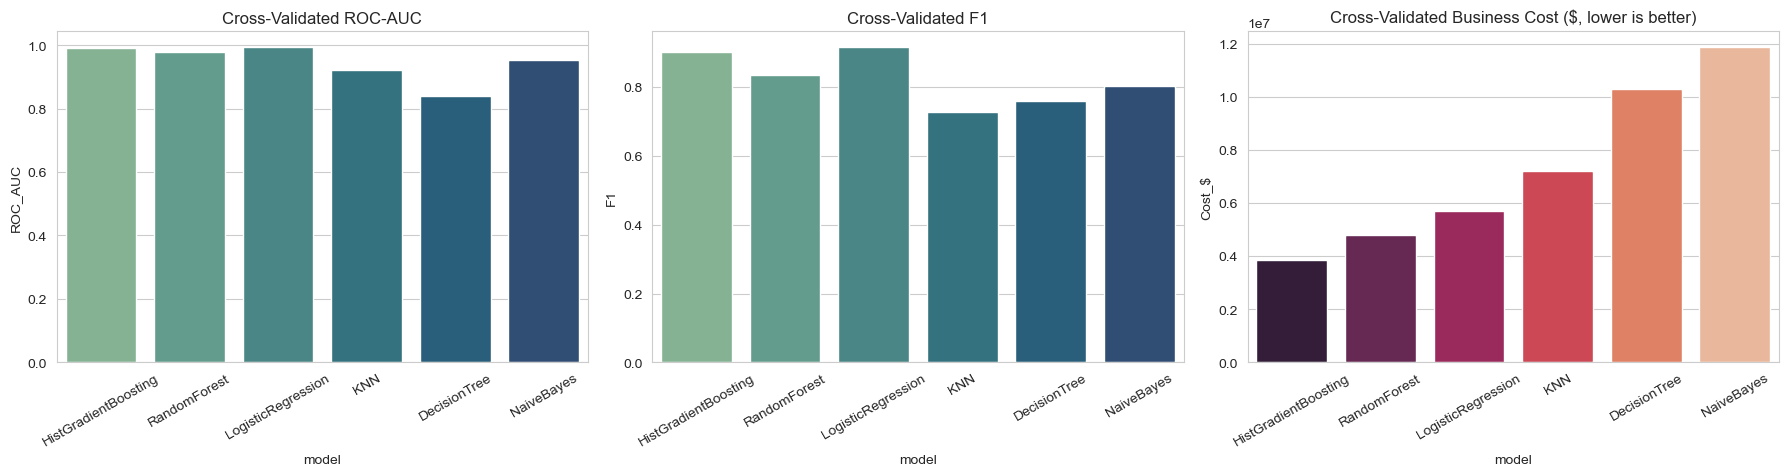

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
order = baseline_df.sort_values('Cost_$')['model']

sns.barplot(data=baseline_df, x='model', y='ROC_AUC', order=order, hue='model', palette='crest', legend=False, ax=axes[0])
axes[0].set_title('Cross-Validated ROC-AUC')
axes[0].tick_params(axis='x', rotation=30)

sns.barplot(data=baseline_df, x='model', y='F1', order=order, hue='model', palette='crest', legend=False, ax=axes[1])
axes[1].set_title('Cross-Validated F1')
axes[1].tick_params(axis='x', rotation=30)

sns.barplot(data=baseline_df, x='model', y='Cost_$', order=order, hue='model', palette='rocket', legend=False, ax=axes[2])
axes[2].set_title('Cross-Validated Business Cost ($, lower is better)')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


### Model selection

Based on the cross-validation results, I take the strongest models forward for tuning. The tree-based models generally give the best business-cost results, while Logistic Regression is kept as an interpretable comparison model.

Keeping Logistic Regression is useful because its coefficients are easier to explain than the output of a more complex ensemble model.


The three measures do not rank the models the same way. Logistic Regression has the highest ROC-AUC and F1, but it ranks third on business cost. HistGradientBoosting has the lowest cost (about $3.85M), followed by Random Forest, while Decision Tree and Naive Bayes are clearly worse on all three measures.

Because a false approval costs far more than a false denial, I select models by business cost, and use ROC-AUC and F1 as supporting measures.

### 4.2 Hyperparameter tuning

I use `RandomizedSearchCV` to tune the Random Forest and HistGradientBoosting models. The search is scored using the **business cost**, rather than only accuracy or ROC-AUC.

A 3-fold cross-validation setup is used for the search to keep the computation manageable. I also allow the numerical imputation method to be part of the search. This shows that preprocessing choices can also affect model performance.


In [22]:
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# --- Random Forest ------------------------------------------------------
rf_pipe = Pipeline([('prep', preprocessor), ('clf', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))])
rf_param_dist = {
    'clf__n_estimators': [100, 200, 300],
    'clf__max_depth': [6, 10, 15, None],
    'clf__min_samples_leaf': [1, 3, 5, 10],
    'clf__class_weight': ['balanced', None],
    'prep__num__imputer__strategy': ['median', 'mean'],
}
rf_search = RandomizedSearchCV(rf_pipe, rf_param_dist, n_iter=10, cv=cv3, scoring=cost_scorer,
                                random_state=RANDOM_STATE, n_jobs=-1)
rf_search.fit(X_train, y_train)
print("Best RF params:", rf_search.best_params_)
print(f"Best RF CV cost: ${-rf_search.best_score_:,.0f}")


Best RF params: {'prep__num__imputer__strategy': 'median', 'clf__n_estimators': 300, 'clf__min_samples_leaf': 1, 'clf__max_depth': None, 'clf__class_weight': 'balanced'}
Best RF CV cost: $8,003,333


In [23]:
# --- HistGradientBoosting ------------------------------------------------
hgb_pipe = Pipeline([('prep', preprocessor), ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE))])
hgb_param_dist = {
    'clf__max_iter': [100, 200, 300],
    'clf__max_depth': [3, 5, 7, None],
    'clf__learning_rate': [0.03, 0.06, 0.1, 0.2],
    'clf__l2_regularization': [0, 0.1, 1.0],
}
hgb_search = RandomizedSearchCV(hgb_pipe, hgb_param_dist, n_iter=10, cv=cv3, scoring=cost_scorer,
                                 random_state=RANDOM_STATE, n_jobs=-1)
hgb_search.fit(X_train, y_train)
print("Best HGB params:", hgb_search.best_params_)
print(f"Best HGB CV cost: ${-hgb_search.best_score_:,.0f}")


Best HGB params: {'clf__max_iter': 100, 'clf__max_depth': 3, 'clf__learning_rate': 0.2, 'clf__l2_regularization': 1.0}
Best HGB CV cost: $6,289,333


In [24]:
# --- Also fit tuned Logistic Regression as our interpretable benchmark ---
logreg_pipe = Pipeline([('prep', preprocessor), ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE))])
logreg_param_dist = {'clf__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}
logreg_search = RandomizedSearchCV(logreg_pipe, logreg_param_dist, n_iter=7, cv=cv3, scoring=cost_scorer,
                                    random_state=RANDOM_STATE, n_jobs=-1)
logreg_search.fit(X_train, y_train)
print("Best LogReg params:", logreg_search.best_params_)
print(f"Best LogReg CV cost: ${-logreg_search.best_score_:,.0f}")


Best LogReg params: {'clf__C': 10}
Best LogReg CV cost: $8,886,000


In [25]:
tuning_summary = pd.DataFrame([
    {'model': 'LogisticRegression (tuned)', 'CV_cost_$': -logreg_search.best_score_},
    {'model': 'RandomForest (tuned)', 'CV_cost_$': -rf_search.best_score_},
    {'model': 'HistGradientBoosting (tuned)', 'CV_cost_$': -hgb_search.best_score_},
]).sort_values('CV_cost_$').reset_index(drop=True)
tuning_summary


,model,CV_cost_$
0,HistGradientBoosting (tuned),6.289333e+06
1,RandomForest (tuned),8.003333e+06
2,LogisticRegression (tuned),8.886000e+06


The model with the lowest cross-validation business cost is selected as the main model. The tuned Logistic Regression model is kept as a challenger because it is easier to interpret and can be used as a useful check against the more complex model.


In [26]:
searches = {'RandomForest': rf_search, 'HistGradientBoosting': hgb_search, 'LogisticRegression': logreg_search}
best_name = tuning_summary.iloc[0]['model'].split(' (')[0]
best_search = searches[best_name]
best_model = best_search.best_estimator_
print(f"Selected primary production model: {best_name}")


Selected primary production model: HistGradientBoosting


## 5. Cost-Optimal Decision Threshold

The default classification threshold of 0.50 is not necessarily the best threshold for this problem. It treats the two types of errors as if they have the same importance, but in this case a false approval costs $50,000 while a false denial costs $8,000.

I therefore calculate the business cost at different thresholds using out-of-fold probabilities from the training data. The threshold with the lowest total cost is selected.


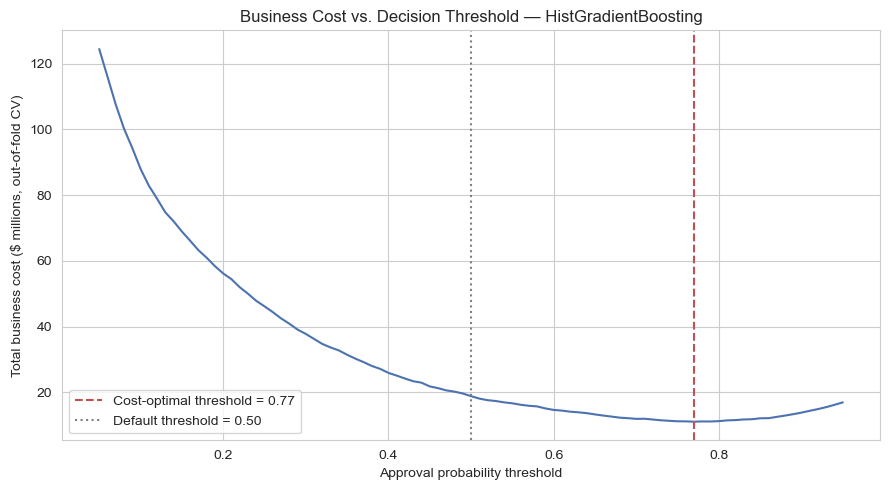

Cost-optimal threshold: 0.77
Cost at optimal threshold:  $11,102,000
Cost at default 0.50:       $18,868,000


In [27]:
from sklearn.base import clone

best_pipe_unfitted = clone(best_search.best_estimator_)
oof_proba = cross_val_predict(best_pipe_unfitted, X_train, y_train, cv=cv3, method='predict_proba', n_jobs=-1)[:, 1]

thresholds = np.linspace(0.05, 0.95, 91)
costs = [business_cost(y_train, (oof_proba >= t).astype(int)) for t in thresholds]
costs = np.array(costs)
best_idx = costs.argmin()
best_threshold = thresholds[best_idx]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, costs / 1e6, color='#4c72b0')
ax.axvline(best_threshold, color='#c44e52', linestyle='--', label=f'Cost-optimal threshold = {best_threshold:.2f}')
ax.axvline(0.5, color='gray', linestyle=':', label='Default threshold = 0.50')
ax.set_xlabel('Approval probability threshold')
ax.set_ylabel('Total business cost ($ millions, out-of-fold CV)')
ax.set_title(f'Business Cost vs. Decision Threshold — {best_name}')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Cost-optimal threshold: {best_threshold:.2f}")
print(f"Cost at optimal threshold:  ${costs[best_idx]:,.0f}")
print(f"Cost at default 0.50:       ${business_cost(y_train, (oof_proba >= 0.5).astype(int)):,.0f}")


Since an incorrect approval is much more expensive, the final threshold is higher than 0.50. This means the model needs to be more confident before approving an application. The trade-off is that some potentially good applicants may be denied, but this can reduce the number of much more expensive defaults.


## 6. Evaluation on the Held-Out Test Set

The test set contains 20% of the original data, which is 4,000 applications. It was not used during model training or tuning.

I evaluate the selected model on this unseen data using both the normal 0.50 threshold and the cost-optimal threshold. I also compare the results with the baseline approaches.


In [28]:
test_proba = best_model.predict_proba(X_test)[:, 1]
test_pred_default = (test_proba >= 0.5).astype(int)
test_pred_optimal = (test_proba >= best_threshold).astype(int)

logreg_test_proba = logreg_search.best_estimator_.predict_proba(X_test)[:, 1]
logreg_test_pred = (logreg_test_proba >= 0.5).astype(int)

print(f"=== {best_name} (primary model) ===")
print(f"Test ROC-AUC: {roc_auc_score(y_test, test_proba):.4f}")
print()
print(f"--- Default threshold (0.50) ---")
print(classification_report(y_test, test_pred_default, target_names=['Denied', 'Approved']))
print(f"Business cost: ${business_cost(y_test, test_pred_default):,.0f}")
print()
print(f"--- Cost-optimal threshold ({best_threshold:.2f}) ---")
print(classification_report(y_test, test_pred_optimal, target_names=['Denied', 'Approved']))
print(f"Business cost: ${business_cost(y_test, test_pred_optimal):,.0f}")
print()
print(f"=== LogisticRegression (interpretable benchmark, default threshold) ===")
print(f"Test ROC-AUC: {roc_auc_score(y_test, logreg_test_proba):.4f}")
print(f"Business cost: ${business_cost(y_test, logreg_test_pred):,.0f}")


=== HistGradientBoosting (primary model) ===
Test ROC-AUC: 0.9927

--- Default threshold (0.50) ---
              precision    recall  f1-score   support

      Denied       0.97      0.98      0.98      3044
    Approved       0.93      0.90      0.92       956

    accuracy                           0.96      4000
   macro avg       0.95      0.94      0.95      4000
weighted avg       0.96      0.96      0.96      4000

Business cost: $3,744,000

--- Cost-optimal threshold (0.77) ---
              precision    recall  f1-score   support

      Denied       0.92      1.00      0.96      3044
    Approved       0.99      0.73      0.84       956

    accuracy                           0.93      4000
   macro avg       0.95      0.86      0.90      4000
weighted avg       0.94      0.93      0.93      4000

Business cost: $2,514,000

=== LogisticRegression (interpretable benchmark, default threshold) ===
Test ROC-AUC: 0.9950
Business cost: $6,274,000


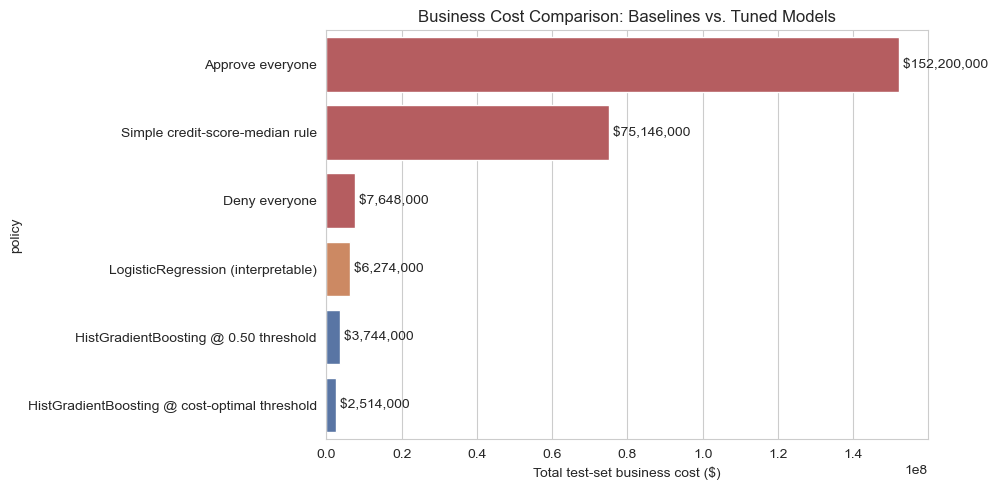

,policy,Cost_$
1,Approve everyone,152200000
2,Simple credit-score-median rule,75146000
0,Deny everyone,7648000
3,LogisticRegression (interpretable),6274000
4,HistGradientBoosting @ 0.50 threshold,3744000
5,HistGradientBoosting @ cost-optimal threshold,2514000


In [29]:
# --- Baselines for comparison ---
deny_all_cost = business_cost(y_test, np.zeros(len(y_test), dtype=int))
approve_all_cost = business_cost(y_test, np.ones(len(y_test), dtype=int))

# Simple heuristic baseline: mimic a basic manual rule (approve if CreditScore above median)
credit_median = X_train['CreditScore'].median()
heuristic_pred = (X_test['CreditScore'] > credit_median).astype(int)
heuristic_cost = business_cost(y_test, heuristic_pred)

baseline_costs = pd.DataFrame([
    {'policy': 'Deny everyone', 'Cost_$': deny_all_cost},
    {'policy': 'Approve everyone', 'Cost_$': approve_all_cost},
    {'policy': 'Simple credit-score-median rule', 'Cost_$': heuristic_cost},
    {'policy': f'LogisticRegression (interpretable)', 'Cost_$': business_cost(y_test, logreg_test_pred)},
    {'policy': f'{best_name} @ 0.50 threshold', 'Cost_$': business_cost(y_test, test_pred_default)},
    {'policy': f'{best_name} @ cost-optimal threshold', 'Cost_$': business_cost(y_test, test_pred_optimal)},
]).sort_values('Cost_$', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#c44e52']*3 + ['#dd8452'] + ['#4c72b0']*2
sns.barplot(data=baseline_costs, y='policy', x='Cost_$', hue='policy', palette=colors, legend=False, ax=ax)
ax.set_xlabel('Total test-set business cost ($)')
ax.set_title('Business Cost Comparison: Baselines vs. Tuned Models')
for i, v in enumerate(baseline_costs['Cost_$']):
    ax.text(v, i, f" ${v:,.0f}", va='center')
plt.tight_layout()
plt.show()
baseline_costs


### 6.1 Confusion matrix and ROC curve

The confusion matrix shows the types of correct and incorrect predictions made by the model. The ROC curve and ROC-AUC provide another way of checking how well the model separates approved and denied applications.


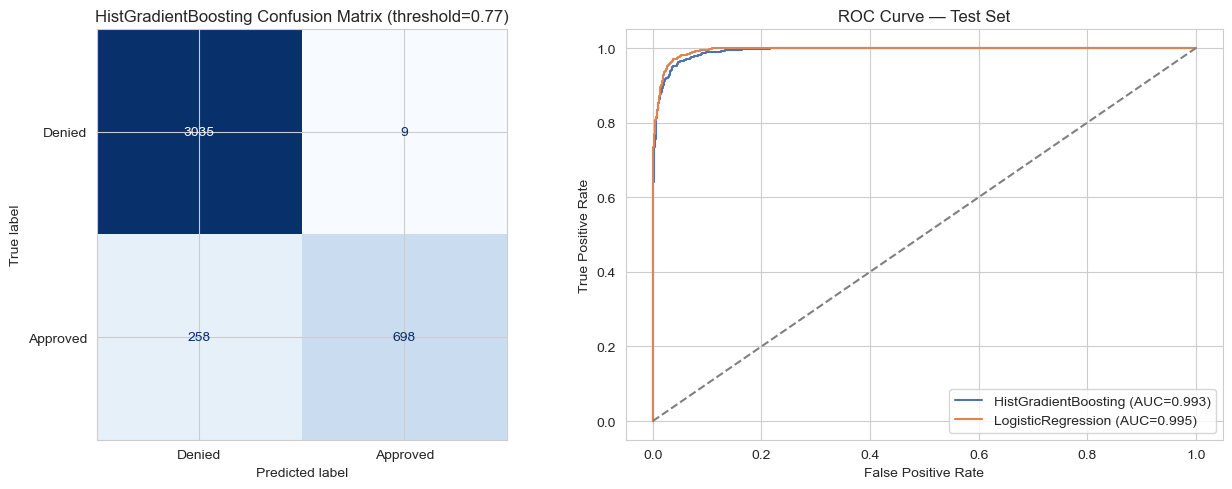

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, test_pred_optimal, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['Denied', 'Approved']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'{best_name} Confusion Matrix (threshold={best_threshold:.2f})')

fpr, tpr, _ = roc_curve(y_test, test_proba)
fpr_lr, tpr_lr, _ = roc_curve(y_test, logreg_test_proba)
axes[1].plot(fpr, tpr, label=f'{best_name} (AUC={roc_auc_score(y_test, test_proba):.3f})', color='#4c72b0')
axes[1].plot(fpr_lr, tpr_lr, label=f'LogisticRegression (AUC={roc_auc_score(y_test, logreg_test_proba):.3f})', color='#dd8452')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — Test Set')
axes[1].legend()

plt.tight_layout()
plt.show()


### 6.2 Performance across data segments

I also check the model across different groups in the data. This is useful because a model can perform well overall but still perform differently for particular groups.


In [31]:
segment_cols = ['EmploymentStatus', 'EducationLevel', 'MaritalStatus', 'HomeOwnershipStatus']
segment_rows = []
for col in segment_cols:
    for val in X_test[col].dropna().unique():
        mask = (X_test[col] == val).values
        if mask.sum() < 30:
            continue
        seg_y = y_test[mask]
        seg_pred = test_pred_optimal[mask]
        seg_auc = roc_auc_score(seg_y, test_proba[mask]) if seg_y.nunique() > 1 else np.nan
        segment_rows.append({
            'feature': col, 'group': val, 'n': mask.sum(),
            'approval_rate_actual': seg_y.mean(),
            'approval_rate_predicted': seg_pred.mean(),
            'AUC': seg_auc,
        })
segment_df = pd.DataFrame(segment_rows)
segment_df.round(3)


,feature,group,n,approval_rate_actual,approval_rate_predicted,AUC
0,EmploymentStatus,Employed,3402,0.242,0.177,0.993
1,EmploymentStatus,Unemployed,287,0.174,0.146,0.990
2,EmploymentStatus,Self-Employed,311,0.264,0.199,0.992
3,EducationLevel,Associate,782,0.207,0.139,0.990
4,EducationLevel,High School,1086,0.153,0.102,0.995
5,EducationLevel,Bachelor,1163,0.279,0.213,0.993
6,EducationLevel,Doctorate,156,0.442,0.365,0.984
7,EducationLevel,Master,620,0.377,0.294,0.989
8,MaritalStatus,Married,1911,0.234,0.177,0.995
9,MaritalStatus,Single,1152,0.240,0.170,0.990


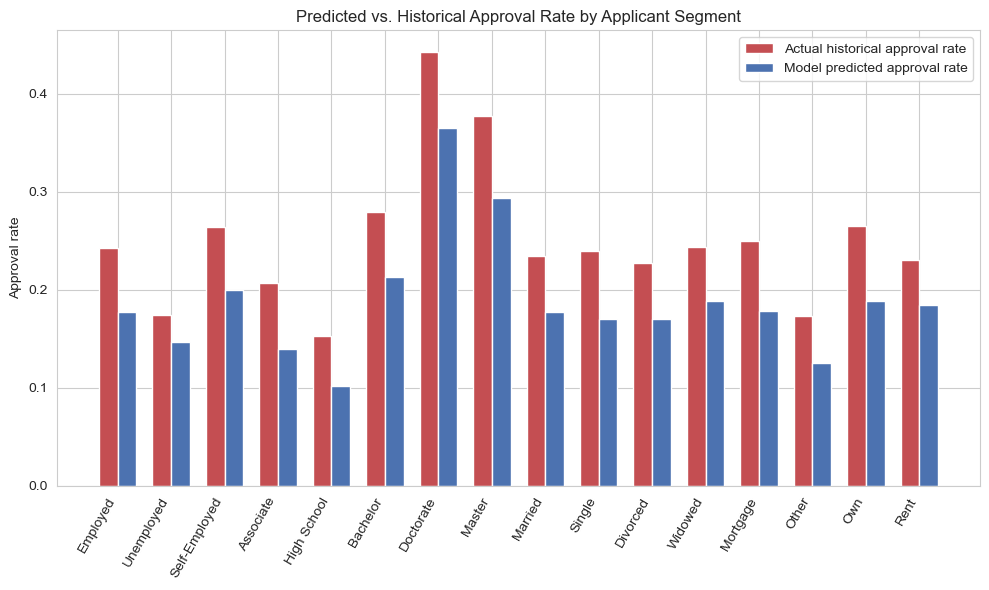

In [32]:
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(segment_df))
width = 0.35
ax.bar(x - width/2, segment_df['approval_rate_actual'], width, label='Actual historical approval rate', color='#c44e52')
ax.bar(x + width/2, segment_df['approval_rate_predicted'], width, label='Model predicted approval rate', color='#4c72b0')
ax.set_xticks(x)
ax.set_xticklabels(segment_df['group'], rotation=60, ha='right')
ax.set_ylabel('Approval rate')
ax.set_title('Predicted vs. Historical Approval Rate by Applicant Segment')
ax.legend()
plt.tight_layout()
plt.show()


### Interpretation

If the predicted approval rate for one group is very different from the historical rate, this does not automatically mean the model is biased, but it is a reason to investigate further. The same applies if the model has a much lower AUC for one group.

These checks should also be repeated after deployment because the data and applicant population can change over time.


## 7. Feature Importance and Interpretability

I examine feature importance using three methods:

1. Tree-based feature importance from the selected ensemble model.
2. Permutation importance, which measures how model performance changes when a feature is disturbed.
3. Logistic Regression coefficients, which provide a more direct way of seeing the direction and strength of relationships.

Using more than one method makes the interpretation more reliable than depending on only one feature-importance measure.


In [33]:
feature_names = best_model.named_steps['prep'].get_feature_names_out()

if hasattr(best_model.named_steps['clf'], 'feature_importances_'):
    importances = best_model.named_steps['clf'].feature_importances_
    imp_df = pd.DataFrame({'feature': feature_names, 'importance': importances}).sort_values('importance', ascending=False).head(15)

    fig, ax = plt.subplots(figsize=(9, 7))
    sns.barplot(data=imp_df, y='feature', x='importance', hue='feature', palette='crest', legend=False, ax=ax)
    ax.set_title(f'{best_name} — Top 15 Feature Importances (impurity-based)')
    plt.tight_layout()
    plt.show()


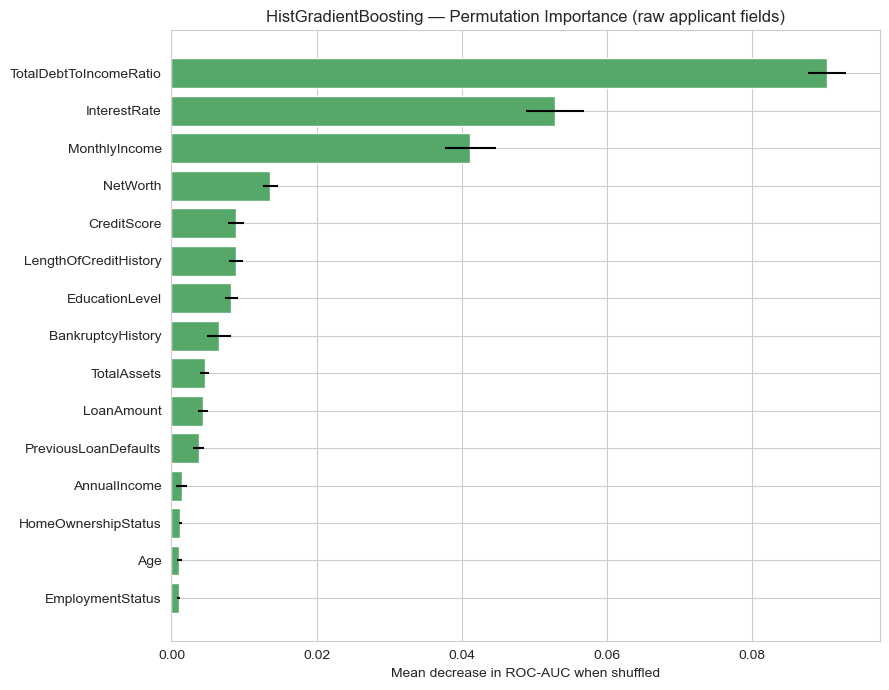

In [34]:
# Permutation importance (model-agnostic, computed on a held-out sample for speed)
perm_sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_test), size=min(1500, len(X_test)), replace=False)
perm_result = permutation_importance(best_model, X_test.iloc[perm_sample_idx], y_test.iloc[perm_sample_idx],
                                      n_repeats=8, random_state=RANDOM_STATE, scoring='roc_auc', n_jobs=1)

perm_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': perm_result.importances_mean,
    'importance_std': perm_result.importances_std,
}).sort_values('importance_mean', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(perm_df['feature'][::-1], perm_df['importance_mean'][::-1], xerr=perm_df['importance_std'][::-1], color='#55a868')
ax.set_xlabel('Mean decrease in ROC-AUC when shuffled')
ax.set_title(f'{best_name} — Permutation Importance (raw applicant fields)')
plt.tight_layout()
plt.show()


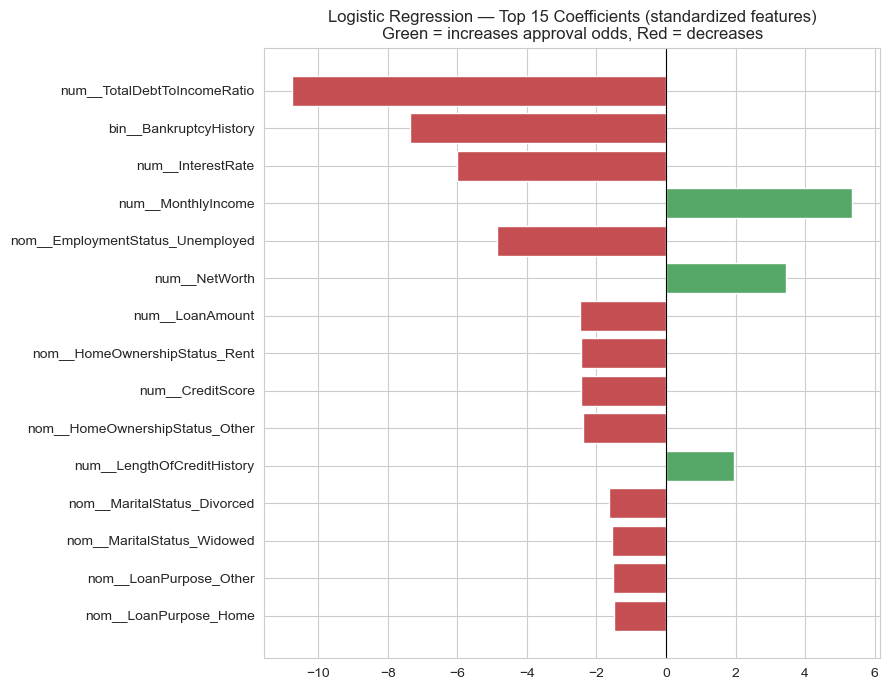

In [35]:
# Logistic regression coefficients (fully interpretable — sign and magnitude both meaningful
# since numeric features were standardized)
logreg_clf = logreg_search.best_estimator_.named_steps['clf']
logreg_features = logreg_search.best_estimator_.named_steps['prep'].get_feature_names_out()
coef_df = pd.DataFrame({'feature': logreg_features, 'coefficient': logreg_clf.coef_[0]})
coef_df['abs_coef'] = coef_df['coefficient'].abs()
coef_df = coef_df.sort_values('abs_coef', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 7))
colors = ['#55a868' if c > 0 else '#c44e52' for c in coef_df['coefficient']]
ax.barh(coef_df['feature'][::-1], coef_df['coefficient'][::-1], color=colors[::-1])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Logistic Regression — Top 15 Coefficients (standardized features)\nGreen = increases approval odds, Red = decreases')
plt.tight_layout()
plt.show()


### Business interpretation

The variables that appear most important are mainly related to affordability and credit behaviour. These include income, debt-to-income measures, credit score, payment history, previous defaults and bankruptcy history.

These results are reasonable for a loan approval problem because they are similar to the factors that a loan officer would normally consider. The fact that the different importance methods point to similar variables also gives more confidence in the model results.


## 8. Secondary Model: Regression on RiskScore

In addition to predicting the approval decision, I build a regression model to predict the continuous `RiskScore`.

The purpose is not to replace the classification model. Instead, the regression model could help produce the existing risk score in a more consistent way from the application information. This would still allow loan officers to make the final decision.


In [36]:
X_reg = df.drop(columns=['LoanApproved', 'RiskScore'])
y_reg = df['RiskScore']

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE)

reg_models = {
    'LinearRegression': LinearRegression(),
    'RandomForestRegressor': RandomForestRegressor(random_state=RANDOM_STATE, n_estimators=200, n_jobs=1),
    'GradientBoostingRegressor': GradientBoostingRegressor(random_state=RANDOM_STATE),
}

reg_results = []
cv_reg = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # not used directly; using KFold via cross_validate default
from sklearn.model_selection import KFold
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name, reg in reg_models.items():
    pipe = Pipeline([('prep', preprocessor), ('reg', reg)])
    cvres = cross_validate(pipe, Xr_train, yr_train, cv=kf,
                            scoring={'mae': 'neg_mean_absolute_error', 'r2': 'r2'}, n_jobs=-1)
    reg_results.append({
        'model': name,
        'MAE': -cvres['test_mae'].mean(),
        'R2': cvres['test_r2'].mean(),
    })

reg_df = pd.DataFrame(reg_results).sort_values('MAE')
reg_df


,model,MAE,R2
1,RandomForestRegressor,1.690519,0.876590
2,GradientBoostingRegressor,1.797444,0.885873
0,LinearRegression,2.798506,0.787637


RandomForestRegressor test MAE=1.70, RMSE=2.72, R2=0.881


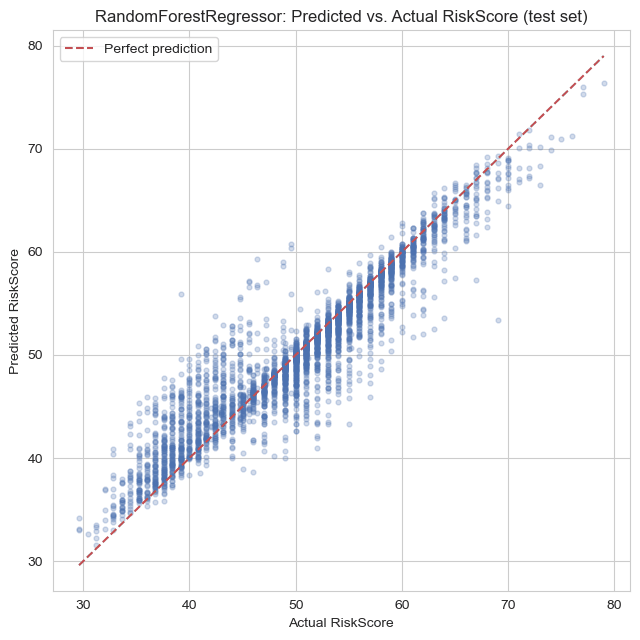

In [37]:
best_reg_name = reg_df.iloc[0]['model']
best_reg = reg_models[best_reg_name]
best_reg_pipe = Pipeline([('prep', preprocessor), ('reg', best_reg)])
best_reg_pipe.fit(Xr_train, yr_train)
yr_pred = best_reg_pipe.predict(Xr_test)

test_mae = mean_absolute_error(yr_test, yr_pred)
test_rmse = mean_squared_error(yr_test, yr_pred) ** 0.5
test_r2 = r2_score(yr_test, yr_pred)
print(f"{best_reg_name} test MAE={test_mae:.2f}, RMSE={test_rmse:.2f}, R2={test_r2:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(yr_test, yr_pred, alpha=0.25, s=12, color='#4c72b0')
lims = [min(yr_test.min(), yr_pred.min()), max(yr_test.max(), yr_pred.max())]
ax.plot(lims, lims, color='#c44e52', linestyle='--', label='Perfect prediction')
ax.set_xlabel('Actual RiskScore')
ax.set_ylabel('Predicted RiskScore')
ax.set_title(f'{best_reg_name}: Predicted vs. Actual RiskScore (test set)')
ax.legend()
plt.tight_layout()
plt.show()


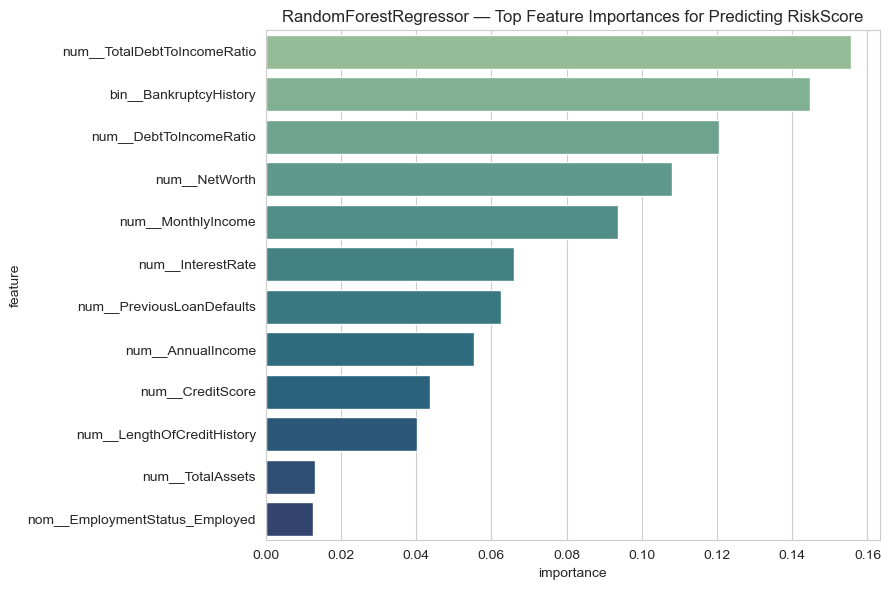

In [38]:
if hasattr(best_reg_pipe.named_steps['reg'], 'feature_importances_'):
    reg_feature_names = best_reg_pipe.named_steps['prep'].get_feature_names_out()
    reg_importances = best_reg_pipe.named_steps['reg'].feature_importances_
    reg_imp_df = pd.DataFrame({'feature': reg_feature_names, 'importance': reg_importances}).sort_values('importance', ascending=False).head(12)

    fig, ax = plt.subplots(figsize=(9, 6))
    sns.barplot(data=reg_imp_df, y='feature', x='importance', hue='feature', palette='crest', legend=False, ax=ax)
    ax.set_title(f'{best_reg_name} — Top Feature Importances for Predicting RiskScore')
    plt.tight_layout()
    plt.show()


The regression model is able to reproduce the existing `RiskScore` fairly closely using the applicant information. This suggests that the score is strongly related to standard credit and affordability variables.

One possible use of this model would therefore be to generate the score consistently for new applications instead of relying on a process that may vary between cases.


## 9. Executive Summary and Business Impact

The analysis shows that machine learning can provide useful support for the loan approval process. The main classification model performs well on the test data, and selecting the threshold based on financial cost gives a much lower cost than the simple baseline rules.

The regression model also performs well in reproducing the existing `RiskScore`, which gives another possible way of using the analysis without fully automating the approval decision.


In [41]:

n_test = len(y_test)
model_cost = business_cost(y_test, test_pred_optimal)

# Savings against both baselines
saving_vs_denyall = deny_all_cost - model_cost
pct_vs_denyall = saving_vs_denyall / deny_all_cost * 100
saving_vs_heuristic = heuristic_cost - model_cost
pct_vs_heuristic = saving_vs_heuristic / heuristic_cost * 100

# What the cost-optimal threshold gives up (approved class)
approved_precision = precision_score(y_test, test_pred_optimal)
approved_recall = recall_score(y_test, test_pred_optimal)

print("=" * 78)
print("EXECUTIVE SUMMARY — KEY RESULTS (computed from this notebook's test results)")
print("=" * 78)
print(f"Primary model: {best_name}  (interpretable benchmark: Logistic Regression)")
print(f"Test ROC-AUC: {roc_auc_score(y_test, test_proba):.3f}")
print(f"Cost-optimal decision threshold: {best_threshold:.2f}  (vs. default of 0.50)")
print()
print(f"Business cost on {n_test:,} held-out test applications:")
print(f"  Deny-everyone baseline:           ${deny_all_cost:,.0f}")
print(f"  Credit-score-median rule:         ${heuristic_cost:,.0f}")
print(f"  {best_name} @ {best_threshold:.2f}:  ${model_cost:,.0f}")
print()
print("Savings from the model:")
print(f"  vs. deny-everyone (stricter baseline): ${saving_vs_denyall:,.0f} ({pct_vs_denyall:.1f}% reduction)")
print(f"  vs. credit-score-median rule:          ${saving_vs_heuristic:,.0f} ({pct_vs_heuristic:.1f}% reduction)")
print()
print("Trade-off at this threshold (approved class):")
print(f"  Precision {approved_precision:.2f}  |  Recall {approved_recall:.2f}")
print(f"  -> about {(1 - approved_recall) * 100:.0f}% of applicants who deserved approval are denied")
print()
print(f"Secondary regression model ({best_reg_name}) predicting RiskScore:")
print(f"  Test MAE: {test_mae:.2f} points   |   Test R2: {test_r2:.3f}")
print("=" * 78)


EXECUTIVE SUMMARY — KEY RESULTS (computed from this notebook's test results)
Primary model: HistGradientBoosting  (interpretable benchmark: Logistic Regression)
Test ROC-AUC: 0.993
Cost-optimal decision threshold: 0.77  (vs. default of 0.50)

Business cost on 4,000 held-out test applications:
  Deny-everyone baseline:           $7,648,000
  Credit-score-median rule:         $75,146,000
  HistGradientBoosting @ 0.77:  $2,514,000

Savings from the model:
  vs. deny-everyone (stricter baseline): $5,134,000 (67.1% reduction)
  vs. credit-score-median rule:          $72,632,000 (96.7% reduction)

Trade-off at this threshold (approved class):
  Precision 0.99  |  Recall 0.73
  -> about 27% of applicants who deserved approval are denied

Secondary regression model (RandomForestRegressor) predicting RiskScore:
  Test MAE: 1.70 points   |   Test R2: 0.881


### Summary for non-technical stakeholders

- **Problem:** loan applications are reviewed manually, which is slow and can treat similar applicants differently.
- **Solution:** a machine learning pipeline that predicts the historical approval decision and also predicts the existing risk score.
- **Financial impact:** a false approval costs about six times more than a false denial ($50,000 against $8,000), so the decision threshold was chosen on business cost (0.77) instead of the default 0.50.
- **Model results:** the tuned HistGradientBoosting model reached a test ROC-AUC of **0.993**. On 4,000 test applications it cost **$2.5M**, against $7.6M for denying everyone and $75.1M for a simple credit-score rule.
- **Trade-off:** the higher threshold makes the model approve fewer applicants. It approves only 73% of the applicants who deserved approval, in exchange for avoiding almost all of the expensive wrong approvals.
- **Important variables:** income, debt levels and credit history were among the strongest predictors across the feature-importance methods.

### Recommendations

1. **Use the model as decision support first.** Loan officers should stay involved, especially in borderline cases.
2. **Use the cost-based threshold, not an automatic 0.50.** Review it if the estimated costs of defaults or missed good loans change.
3. **Monitor performance by group.** Check approval rates and model performance regularly to catch unexpected differences.
4. **Keep Logistic Regression as an interpretable comparison.** It helps explain the main relationships and gives a simpler model to check the ensemble against.
5. **Consider the `RiskScore` model as an early step.** It produces an existing score consistently without automating the approval decision.

### Limitations

- **Historical decisions:** `LoanApproved` records past human decisions, not confirmed repayment or default. If those decisions were biased or inconsistent, the model can learn the same patterns.
- **Fairness:** the data has no protected-class information such as race or gender, so a full fair-lending analysis is not possible. The employment, education, marital-status and home-ownership checks are only a limited substitute.
- **Changing conditions:** the data is a snapshot, and performance may change as the economy or the applicant population changes.
- **Cost estimates:** the $8,000 and $50,000 costs are averages and will differ between loans. A future model could estimate expected loss for each applicant.
- **Fewer approvals:** the cost-optimal threshold denies some creditworthy applicants, so the business should confirm it accepts that trade-off.

### Next steps

- Add real repayment and default outcomes when available, and eventually train the model on them directly.
- Carry out a more detailed fairness review before any automated use.
- Run the model in an advisory setting first, and track how often officers agree with or override it.
